<a href="https://colab.research.google.com/github/kic24/ee1deca/blob/main/02_ML_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression


---


Regression is a supervised learning technique used to predict a continuous value from one or more input variables.

For example, consider the diabetes dataset$^\dagger$. Suppose we want to predict how a patient's diabetes will progress based on information such as age, body mass index (BMI), blood pressure, and serum measurements. These patient attributes are the independent variables, or features, while disease progression is the dependent variable, or target we want to predict.

One common regression method is linear regression. As the name suggests, linear regression assumes that the relationship between the input variables and the target can be approximated using a linear equation.

For multiple input variables, the model can be written as:

$$
\hat{y} = w_0x_0 + w_1x_1 + w_2x_2 + \ldots + w_nx_n = \sum_{i=0}^{n}w_ix_i = \mathbf{W}^T\mathbf{X}
$$

Here, $\hat{y}$ represents the dependent variable (diabetes progression), $x_1, x_2, \ldots, x_n$ denote the independent variables (age, BMI, blood pressure, etc.), and $w_0, w_1, w_2, \ldots, w_n$ are the coefficients that determine the impact of each independent variable on the dependent variable. Hence, $x_0=1$ to account the bias term.

During training, linear regression tries to find values for these coefficients that make the model's predictions as close as possible to the actual values in the dataset. In other words, it finds the line, or with multiple features, the linear relationship that best fits the observed data.

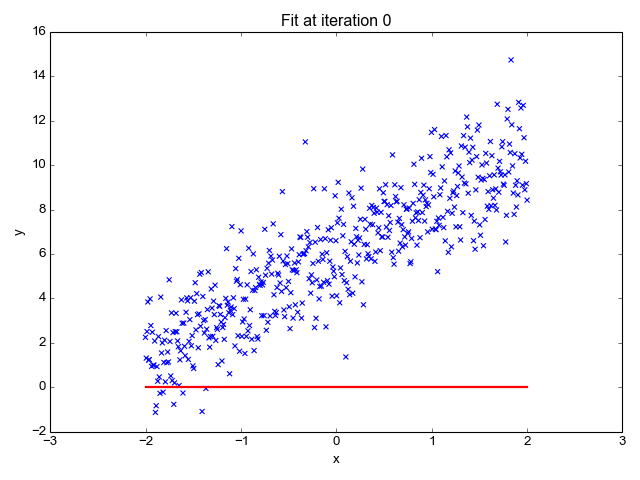

[[Image Source]](https://towardsdatascience.com/linear-regression-the-easier-way-6f941aa471ea)

To measure how well our regression model is performing, we can use Mean Squared Error (MSE). MSE measures the average squared difference between the model's predictions and the actual values.

For the diabetes dataset, it is calculated across all patients as:

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

In this equation, $y_i$ represents the actual diabetes progression value for the $i^{th}$ patient, and $\hat{y}_i$ signifies the predicted value from our regression model. The squared differences represent the errors made by the model, and averaging them gives us a single value that summarizes the model's overall prediction error.

A lower MSE generally means that the predicted values are closer to the actual values.




> $\dagger$: More information on the diabetes dataset will be revealed as we go throughout the tutorial.



# Diabetes Dataset


The diabetes dataset, available in the `sklearn.datasets` module, is a commonly used dataset for regression examples. It contains ten baseline variables (age, sex, BMI, average blood pressure, and six blood serum measurements) for 442 diabetes patients. The target variable is a numerical measure of diabetes progression one year after the initial measurements were taken.

Because the target is a continuous value, this dataset works well for demonstrating regression models such as linear regression. In our example, we will use the patient features to train a model that predicts diabetes progression.

To load the diabetes dataset in your Colab notebook, you can use the following code:

```python
from sklearn.datasets import load_diabetes

# Load the diabetes dataset
diabetes = load_diabetes()

# Access data and target variables
X = diabetes.data
y = diabetes.target

```


In this tutorial, we will use the diabetes dataset to address a linear regression problem employing both the gradient descent and closed-form solution methods.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

In [2]:
# Load the diabetes dataset
diabetes = load_diabetes()

# Print data description
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:
# print feature names used in the data
diabetes.feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

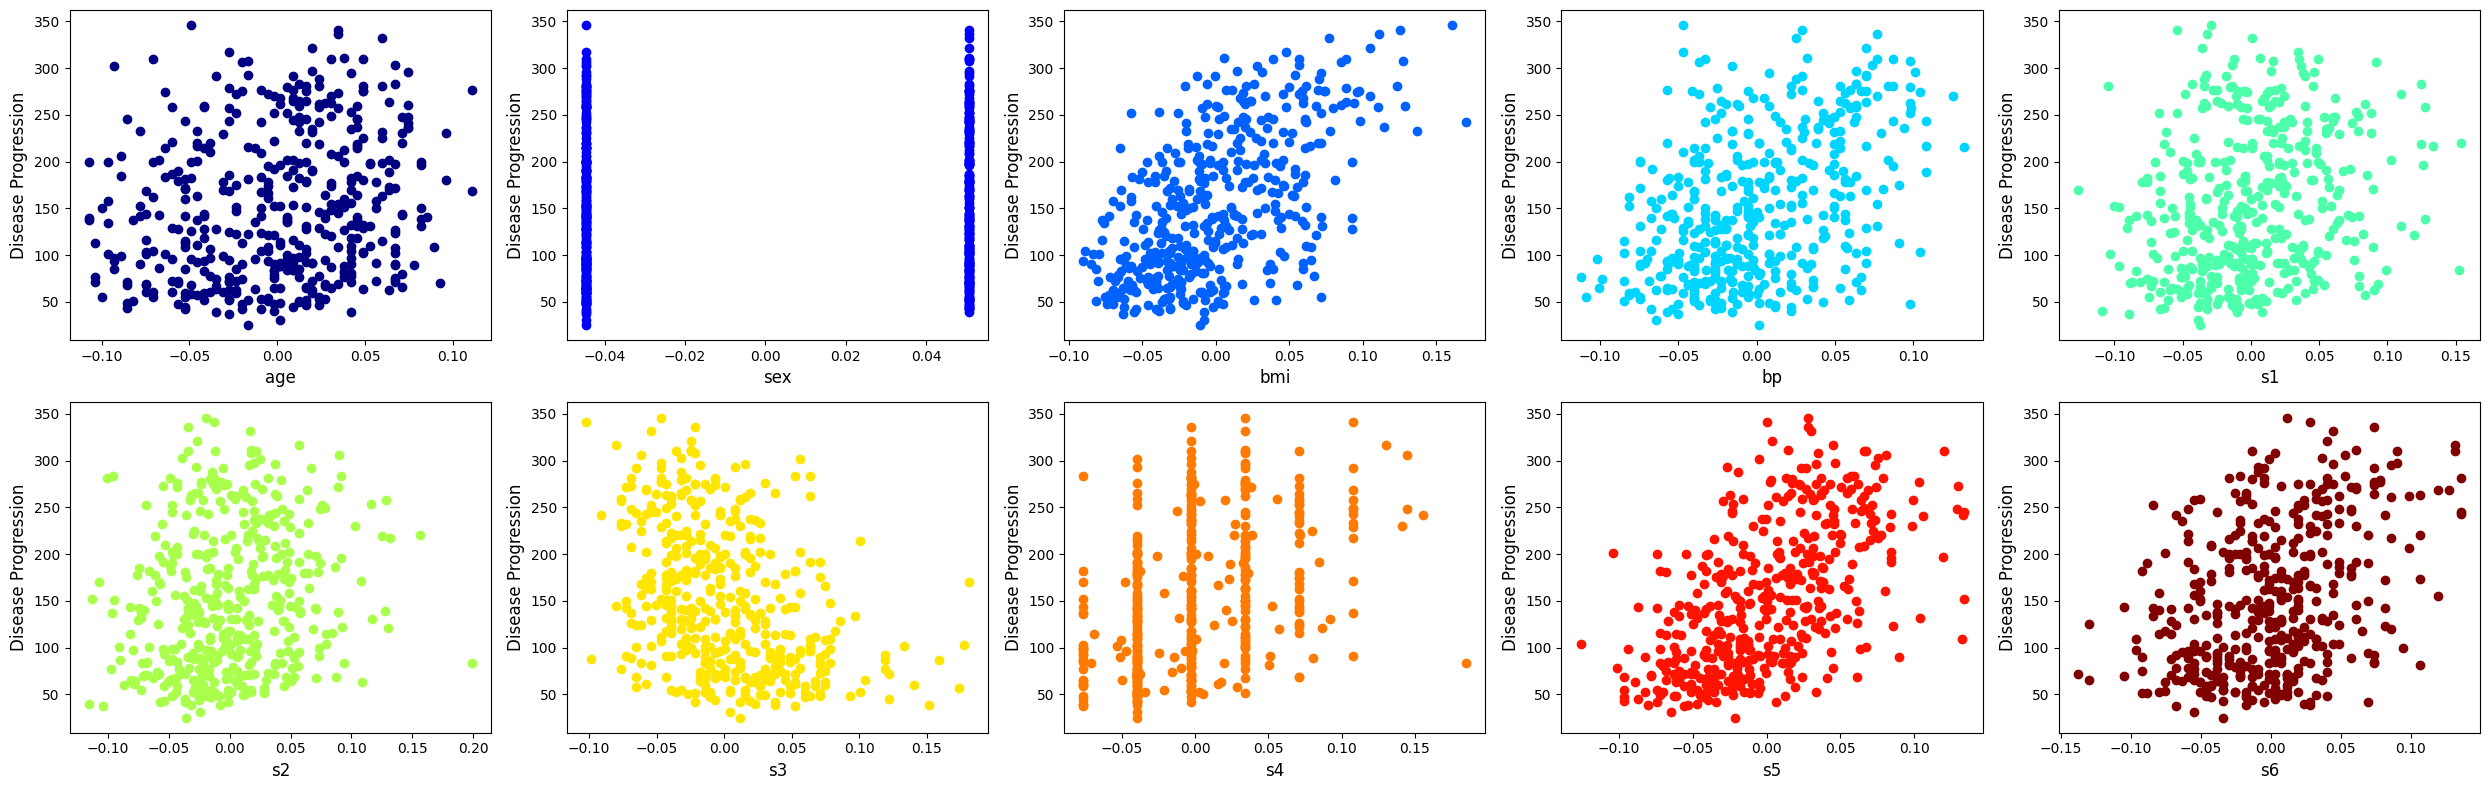

In [4]:
# Create a DataFrame to store the data and target
diabetes_data = pd.DataFrame(data=diabetes['data'], columns=diabetes['feature_names'])
diabetes_data["DP"] = diabetes['target']

# Set the size of each individual plot
plot_width = 5
plot_height = 4

# Calculate the number of rows and columns for the grid layout
num_features = len(diabetes.feature_names)
num_cols = 5
num_rows = (num_features + num_cols - 1) // num_cols

# Create subplots in a grid layout
fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(plot_width * num_cols, plot_height * num_rows))

# Flatten the axes array to iterate over all the subplots
axes = axes.flatten()

# Define a colormap for assigning different colors to each feature plot
colors = plt.cm.jet(np.linspace(0, 1, num_features))

# Plot each feature against the target variable in separate subplots
for index, feature_name in enumerate(diabetes.feature_names):
    axes[index].scatter(diabetes.data[:, index], diabetes.target, color=colors[index])
    axes[index].set_ylabel('Disease Progression', size=12)
    axes[index].set_xlabel(feature_name, size=12)

# Hide any remaining empty subplots
for i in range(num_features, num_rows * num_cols):
    fig.delaxes(axes[i])

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

# Gradient Descent


Another way to train a linear regression model is to use Gradient Descent. Unlike the closed-form solution, which computes the model weights directly, Gradient Descent finds the weights gradually through a series of updates. This makes it useful when working with large datasets or when computing a matrix inverse would be expensive.

The goal of Gradient Descent is to find the model weights that minimize the Mean Squared Error (MSE). Instead of solving for these weights in a single step, the algorithm starts with an initial set of values and updates them repeatedly.

At each iteration, Gradient Descent looks at how the MSE changes with respect to each weight. This information is given by the gradient. Since the gradient points in the direction of the steepest increase in error, we update the weights in the opposite direction.

The update for a weight $w_j$ can be written as:

$
w_j = w_j - \alpha \cdot \frac{\partial}{\partial w_j} \text{MSE}(w)
$

Here, $w_j$ represents the $j$th weight, and $\alpha$ is the learning rate, which determines the step size in each iteration. The partial derivative with respect to $w_j$ indicates how much the MSE changes as we vary the $j$th weight.


The choice of the learning rate is crucial. A larger learning rate may cause overshooting, while a smaller rate might lead to slow convergence. It's a balancing act to find an appropriate learning rate that allows for a steady convergence towards the minimum MSE.


The update process continues until the algorithm reaches a stopping condition. For example, we might stop when the change in MSE becomes very small or after a fixed number of iterations.. This can be illustrated in the figure below

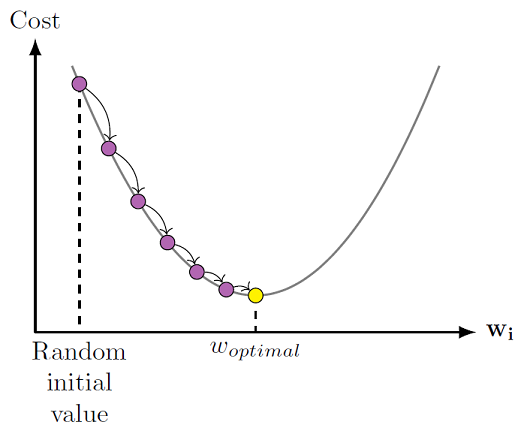



In [ ]:
# function to perform the prediction by multiplying the inputs with weights
def predict_dp(X,W):
    return np.dot(X,W)

In [ ]:
# function to calculate the cost (here we use MSE)
def cost(X,W,Y):
    prediction = predict_dp(X,W)
    return ((Y - prediction)**2).mean()

In [ ]:
# function to plot the predicted line vs real data
def plot_line(X,W,Y):
    """Plot a line from slope and intercept"""
    y_vals = predict_dp(X,W)
    plt.figure(figsize=(5, 4))
    plt.xlabel('Age')
    plt.ylabel('Disease Progression (DP)')
    plt.scatter(X[:,1],Y, color='red', label='Actual')
    plt.plot(X[:,1], y_vals, color='black', label='Predicted')
    plt.legend(loc='upper left')
    plt.show()

In [ ]:
# function to plot cost variations as the algorithm iterate
def plot_cost(cost):
    plt.figure(figsize=(5, 4))
    plt.plot(range(1, len(cost) + 1), cost)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.show()

In [ ]:
# function that applies GD and fit the algorithm
def fit(n_iter,X,Y,lr):
    W0 = []
    W1 = []
    costs = []
    # Incorporate the bias term
    X = np.column_stack((np.ones(len(X)),X))
    #N = len(diabetes['target'])
    W = np.zeros(2)
    c = 0
    for i in range(n_iter):
        pred = predict_dp(X,W)
        W[0] += lr *(Y - pred).mean()
        W[1] += lr *((Y - pred)* X[:,1]).mean()
        W = np.array([W[0],W[1]])
        J = cost(X,W,Y)
        W0.append(W[0])
        W1.append(W[1])
        costs.append(J)
        c = i + 1
        if i%1000==0:
            print(f"Iteration: {i}, Cost = {J}, Weights = {W}")
            plot_line(X,W,Y)
    print(f"Iteration: {c}, Cost = {J}, Weights = {W}")
    plot_line(X,W,Y)
    plot_cost(costs)

Iteration: 0, Cost = 6160.479227680582, Weights = [136.92013575   0.6193773 ]


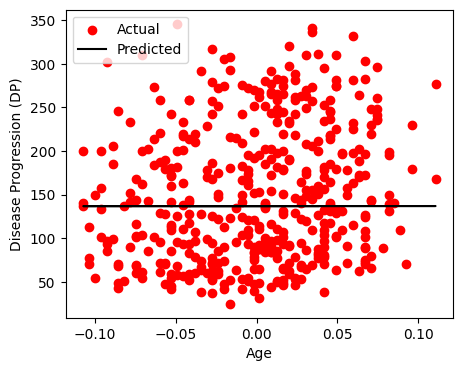

Iteration: 1000, Cost = 5724.084173552051, Weights = [152.13348416 264.64292904]


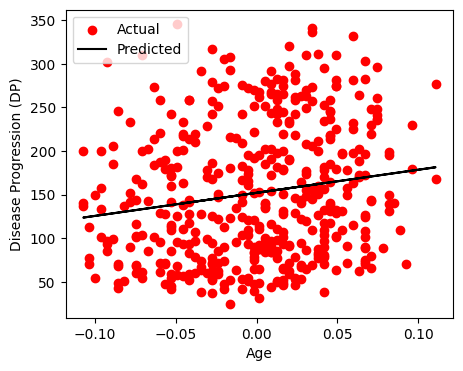

Iteration: 2000, Cost = 5720.6070282403925, Weights = [152.13348416 299.03284372]


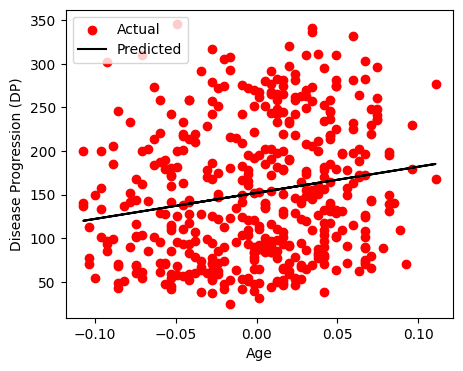

Iteration: 3000, Cost = 5720.548035346757, Weights = [152.13348416 303.51224044]


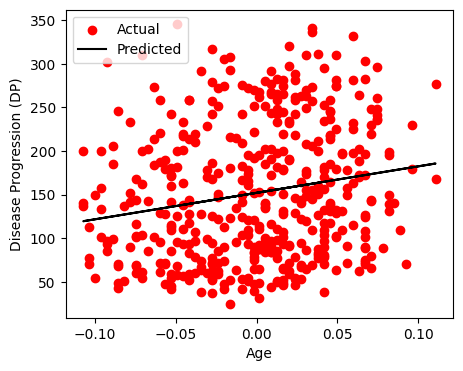

Iteration: 4000, Cost = 5720.547034479326, Weights = [152.13348416 304.09569624]


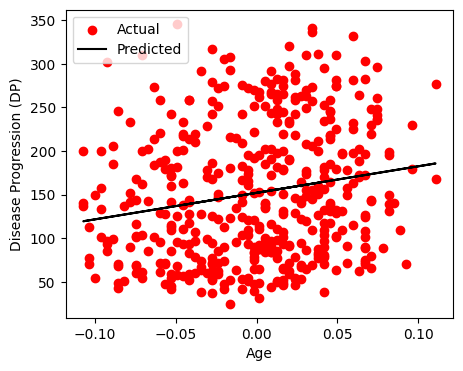

Iteration: 5000, Cost = 5720.547017498711, Weights = [152.13348416 304.17169323]


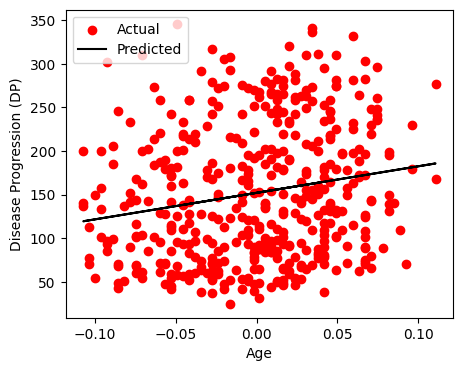

Iteration: 6000, Cost = 5720.54701721062, Weights = [152.13348416 304.18159208]


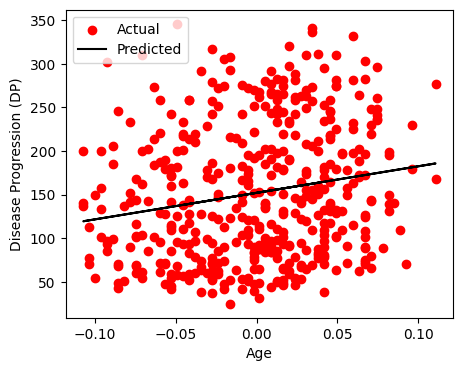

Iteration: 7000, Cost = 5720.547017205731, Weights = [152.13348416 304.18288143]


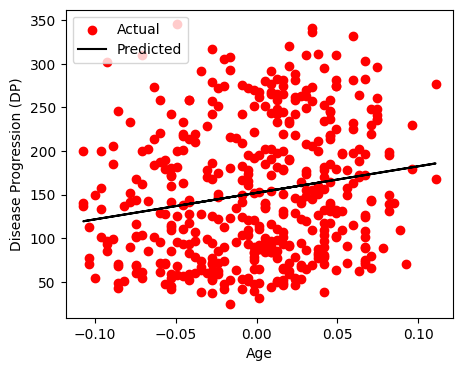

Iteration: 8000, Cost = 5720.547017205648, Weights = [152.13348416 304.18304938]


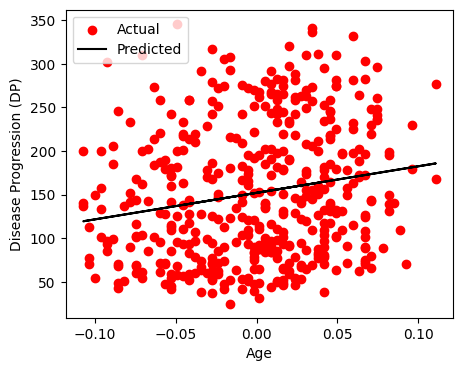

Iteration: 9000, Cost = 5720.5470172056475, Weights = [152.13348416 304.18307125]


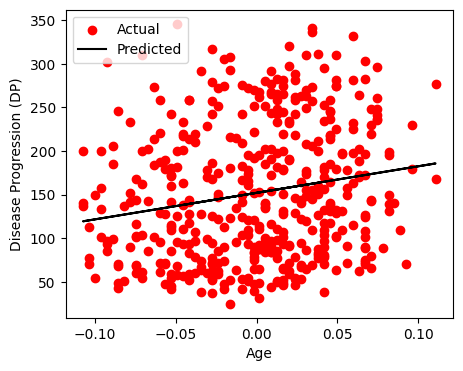

Iteration: 10000, Cost = 5720.547017205647, Weights = [152.13348416 304.1830741 ]


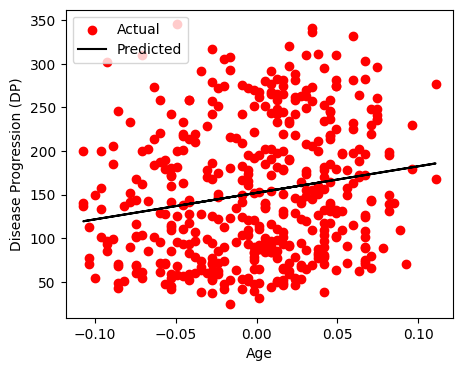

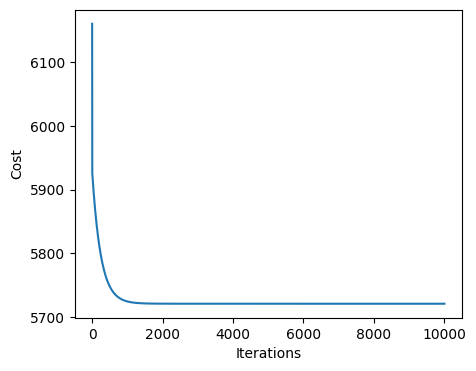

In [ ]:
lr = 0.9
n_iter=10000
X = diabetes_data["age"]
Y = diabetes_data["DP"]
fit(n_iter,X,Y,lr)

## Task 1 [10 marks]

Update the Gradient Descent (GD) code to predict disease progression (DP) based on two different features: body mass index (BMI) and average blood pressure (BP). Follow the same procedure as before to determine the optimal weights for each case.

Execute the modified code to generate the following outcomes:

1. Plot illustrating the actual data points and the predicted regression line for disease progression vs BMI according to the final weights obtained.
2. Plot illustrating the actual data points and the predicted regression line for disease progression vs average blood pressure (BP) according to the final weights obtained.
3. Display the final weights and cost (MSE) obtained after the optimisation process for both cases (keep the values to be used in the same table of tasks 2 and 3).

In [5]:
# Task 1
# =============================================================================
# TASK 1  [10 marks]  --  Gradient Descent (GD) using BMI and BP
# Paste in cell: "# Task 1"
# -----------------------------------------------------------------------------
# Two small updates to the tutorial code:
#   * plot_line() takes the feature name, so the x-axis is labelled correctly
#     (the original hard-coded 'Age').
#   * fit() now RETURNS the final weights + cost history, so the numbers can be
#     re-used in the comparison tables of Tasks 2 and 3.
# The maths/updates are exactly the ones used in the tutorial.
# =============================================================================

# ---- prediction (unchanged) -------------------------------------------------
def predict_dp(X, W):
    """X = design matrix [1, feature] of shape (n, 2);  W = [w0, w1]."""
    return np.dot(X, W)

# ---- cost function = Mean Squared Error (unchanged) -------------------------
def cost(X, W, Y):
    prediction = predict_dp(X, W)
    return ((Y - prediction) ** 2).mean()

# ---- scatter of the data + fitted regression line ---------------------------
def plot_line(X, W, Y, feature_name='Feature'):
    y_vals = predict_dp(X, W)
    order = np.argsort(X[:, 1])            # sort x so the line is drawn cleanly
    plt.figure(figsize=(5, 4))
    plt.xlabel(feature_name)
    plt.ylabel('Disease Progression (DP)')
    plt.scatter(X[:, 1], Y, color='red', label='Actual')
    plt.plot(X[:, 1][order], y_vals[order], color='black', label='Predicted')
    plt.legend(loc='upper left')
    plt.title(f'DP vs {feature_name}')
    plt.show()

# ---- cost against iterations (unchanged) ------------------------------------
def plot_cost(costs):
    plt.figure(figsize=(5, 4))
    plt.plot(range(1, len(costs) + 1), costs)
    plt.xlabel('Iterations')
    plt.ylabel('Cost (MSE)')
    plt.title('GD convergence')
    plt.show()

# ---- UPDATED gradient-descent fit ------------------------------------------
def fit(n_iter, X, Y, lr, feature_name='Feature', plot_every=2000):
    """X = ONE raw feature (1-D array). Returns (final weights W, cost history)."""
    X = np.column_stack((np.ones(len(X)), X))   # bias column x0 = 1
    W = np.zeros(2)                             # start from w0 = w1 = 0
    costs = []
    for i in range(n_iter):
        pred = predict_dp(X, W)
        err = Y - pred
        # same update rules as the tutorial (the factor 2 of the derivative
        # is absorbed into the learning rate)
        W[0] += lr * err.mean()                 # d(MSE)/d(w0) direction
        W[1] += lr * (err * X[:, 1]).mean()     # d(MSE)/d(w1) direction
        J = cost(X, W, Y)
        costs.append(J)
        if i % plot_every == 0:                 # progress snapshot
            print(f"Iteration: {i}, Cost = {J}, Weights = {W}")
            plot_line(X, W, Y, feature_name)
    print(f"Iteration: {n_iter}, Cost = {J}, Weights = {W}")
    plot_line(X, W, Y, feature_name)            # FINAL fitted line
    plot_cost(costs)                            # FINAL convergence curve
    return W, costs




=================== GD: BMI ===================
Iteration: 0, Cost = 6153.033958469029, Weights = [136.92013575   1.93323922]


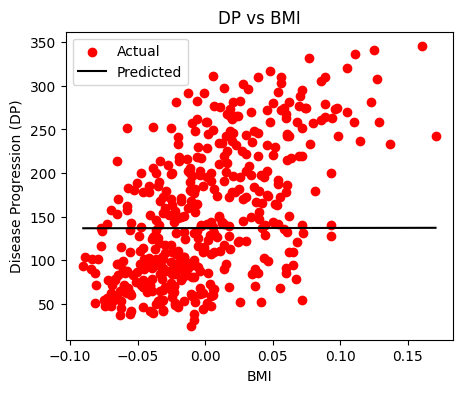

Iteration: 2000, Cost = 3891.041229785707, Weights = [152.13348416 933.36003748]


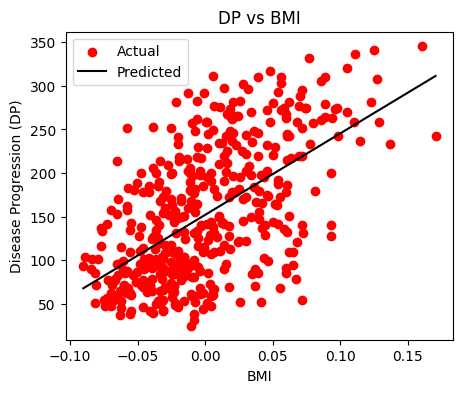

Iteration: 4000, Cost = 3890.4567537462904, Weights = [152.13348416 949.16252979]


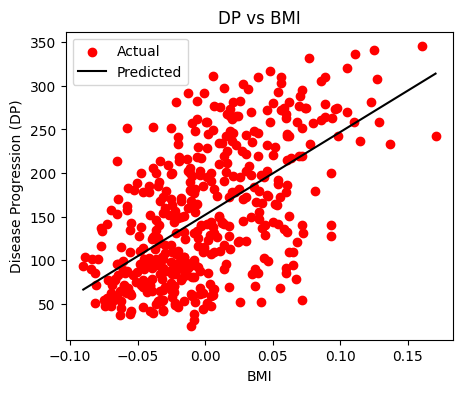

Iteration: 6000, Cost = 3890.4565855097117, Weights = [152.13348416 949.43063326]


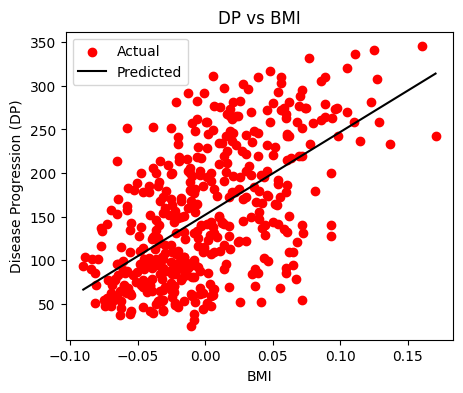

Iteration: 8000, Cost = 3890.4565854612865, Weights = [152.13348416 949.43518188]


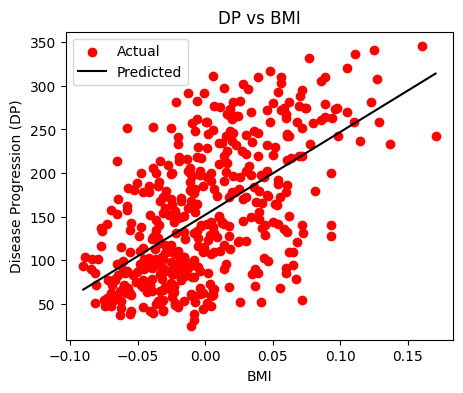

Iteration: 10000, Cost = 3890.456585461273, Weights = [152.13348416 949.43525905]


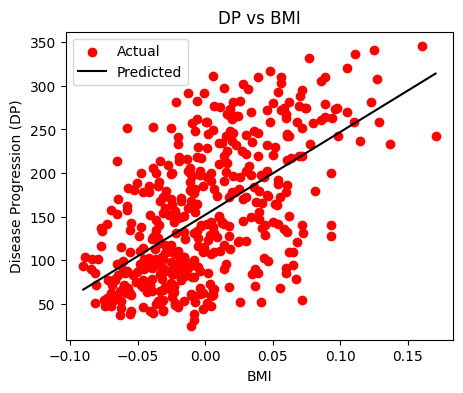

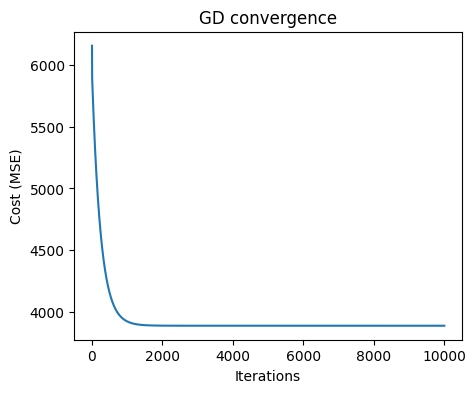

BMI -> w0 = 152.133484 | w1 = 949.435259 | final MSE = 3890.456585

=================== GD: BP ===================
Iteration: 0, Cost = 6156.628899189452, Weights = [136.92013575   1.4553494 ]


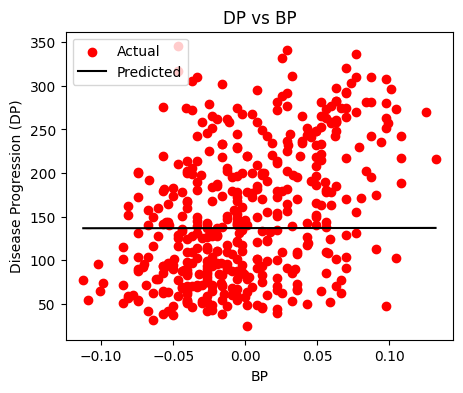

Iteration: 2000, Cost = 4774.44522803898, Weights = [152.13348416 702.6367742 ]


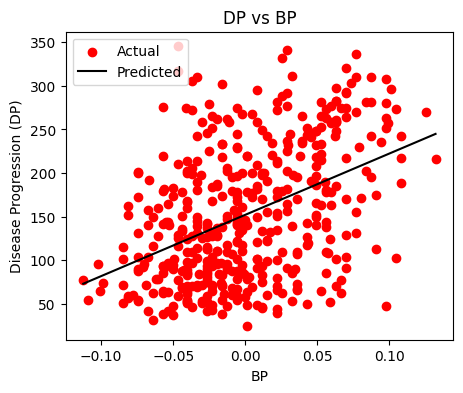

Iteration: 4000, Cost = 4774.113997738033, Weights = [152.13348416 714.53294693]


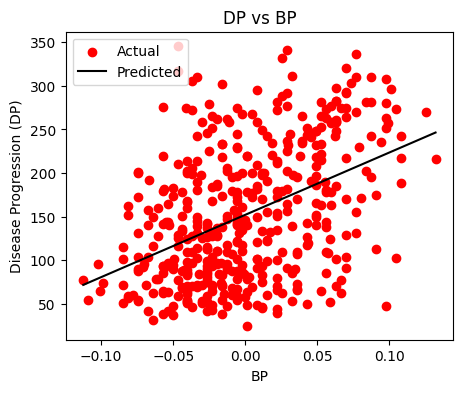

Iteration: 6000, Cost = 4774.113902396139, Weights = [152.13348416 714.73477618]


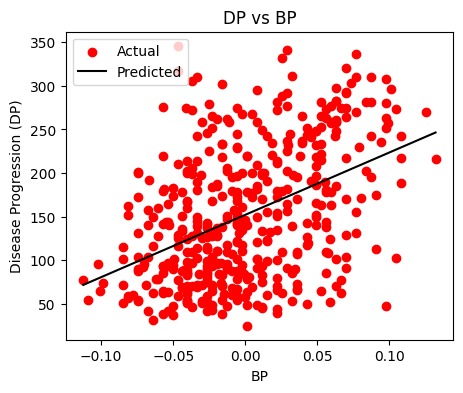

Iteration: 8000, Cost = 4774.113902368695, Weights = [152.13348416 714.7382004 ]


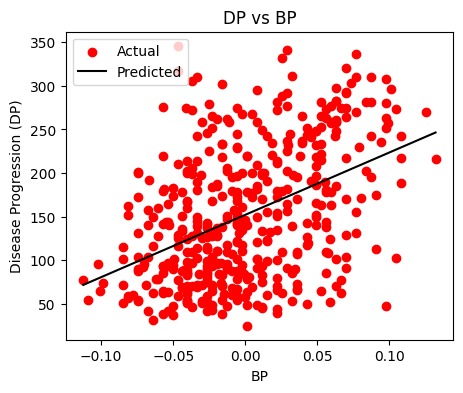

Iteration: 10000, Cost = 4774.113902368687, Weights = [152.13348416 714.73825849]


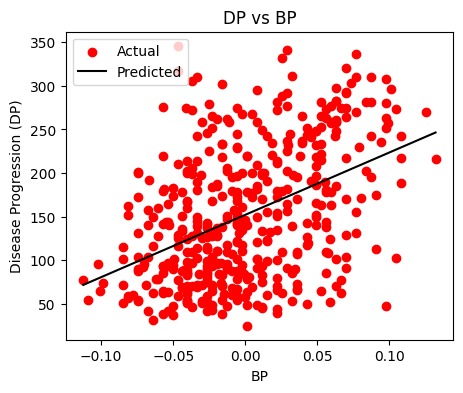

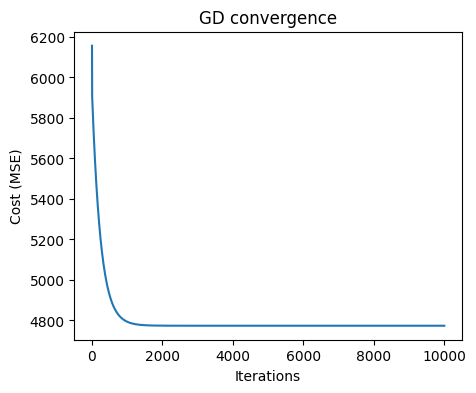

BP -> w0 = 152.133484 | w1 = 714.738258 | final MSE = 4774.113902

GD results (Task 1):
Feature  w0 (intercept)  w1 (slope)         MSE
    BMI      152.133484  949.435259 3890.456585
     BP      152.133484  714.738258 4774.113902


In [6]:
# Task 1 (continued)
# -----------------------------------------------------------------------------
# TASK 1 (continued) -- run GD for BMI and for BP  (items 1, 2 and 3)
# Paste in cell: "# Task 1 (continued)"
# -----------------------------------------------------------------------------
lr, n_iter = 0.9, 10000        # same hyper-parameters as the 'age' example.
                               # Every feature is scaled so that sum(x^2) = 1,
                               # therefore the same lr converges for all of them.
Y = diabetes_data['DP'].to_numpy()

W_gd, gd_costs = {}, {}        # stored for the tables in Tasks 2 and 3

for feat, label in [('bmi', 'BMI'), ('bp', 'BP')]:
    print(f'\n=================== GD: {label} ===================')
    x = diabetes_data[feat].to_numpy()
    W, costs = fit(n_iter, x, Y, lr, feature_name=label)
    W_gd[label], gd_costs[label] = W, costs
    print(f'{label} -> w0 = {W[0]:.6f} | w1 = {W[1]:.6f} | final MSE = {costs[-1]:.6f}')

# Item 3: final weights + cost for both cases, in one small table
gd_summary = pd.DataFrame([
    {'Feature': f, 'w0 (intercept)': W_gd[f][0], 'w1 (slope)': W_gd[f][1],
     'MSE': gd_costs[f][-1]} for f in ['BMI', 'BP']])
print('\nGD results (Task 1):')
print(gd_summary.round(6).to_string(index=False))
# Sanity check: the features are mean-centred, so w0 must be ~ mean(DP) = 152.1335
# for every single-feature model, and BMI must give a lower MSE than BP.


# Closed-form Solution

One way to find the weights of a linear regression model is to solve for them directly. This is known as the closed-form solution, or the normal equation:

$
w = (X^T X)^{-1} X^T y
$

Here:
- $w$ is the weight vector.
- $X$ is the design matrix composed of feature vectors.
- $y$ is the vector of target values.

This equation gives the weights that minimize the sum of squared errors. It comes from taking the derivative of the error function with respect to $w$, setting it equal to zero, and solving for the weights.

The closed-form solution works well when the number of features is relatively small. However, computing $(X^T X)^{-1}$ can become expensive as the number of features grows. This issues can be handled using iterative optimisation methods such as Gradient Descent.

## Task 2 [40 marks]

In this task, you will solve the same regression problem from Task 1 using the closed-form solution. Use the same two features, BMI and average blood pressure (BP), separately.

1. Implement a colsed-form solution code to solve the same problem.

2. Compare the final weights and Mean Squared Error (MSE) obtained using Gradient Descent with those obtained using the closed-form solution. Summarise the results in a table. You will use the same table again in Task 3.

3. For each feature, plot the original data points together with the regression line obtained using the closed-form solution, similar to the plots produced in Task 1.



> **Hint:** explore the `numpy.linalg.pinv` function available within the Numpy library. This function offers the capability to compute the (Moore-Penrose) pseudo-inverse of a matrix, which can significantly aid your calculations.



In [ ]:
# Task 2


In [ ]:
# Task 2 (continued)


In [ ]:
# Task 2 (continued)



In [ ]:
# Task 2 (continued)


# Scikit-learn Implementation

Scikit-learn provides a convenient and user-friendly way to do so. First, you'll need to import the necessary module:
```python
from sklearn.linear_model import LinearRegression
```

You can initialise the regressor with various parameters:
> More information can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

## Task 3 [15 marks]

In this task, you will solve the same regression problems from Tasks 1 and 2 using scikit-learn. Use BMI and average blood pressure (BP) separately, as before.

1. Implement a code using sckit-learn to solve the same problems as in tasks 1 & 2.

2. Compare the final weights and Mean Squared Error (MSE) obtained using:
 - Gradient Descent
 - Closed-form solution
 - Scikit-learn
 Add the scikit-learn results to the same comparison table used in Tasks 1&2.

3. Generate a plot that illustrates the line produced by scikit-learn package in relation to the original dataset, as in the GD and closed-form examples.

4. Use the following command from scikit-learn to estimate the MSE error on each case.
  ```python
  from sklearn.metrics import mean_squared_error
  ```

In [ ]:
# Task 3



In [ ]:
# Task 3 (continued)


In [ ]:
# Task 3 (continued)


In [ ]:
# Task 3 (continued)


## Task 4 [10 marks]

Write a code that use all the 10 features in the data as inputs to the regressor in order to predict the disease pregression (DP). Then, rank the features by their importance (using their absolute weight values). Finally, craete a plot that shows how the mean squared error (MSE) changes as you progressively add features, starting from the most important ones.

From the resulting plot, identify the approximate number of features you would choose to keep (i.e. the point where adding more features no longer significantly reduces the MSE (the 'elbow point')). Treat this as a visual, judgment-based choice, and include a brief justification in your write-up referring to what you observe in the plot.





> You are allowed to import the following in this task:
```python
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
```



In [ ]:
# Task 4



# k-fold Validation



When evaluating a machine learning model, we want to know how well it is likely to perform on data it has not seen during training. A single train/test split can give us an estimate, but the result may depend on how the data happened to be divided. **k-Fold Cross-Validation** provides another way to evaluate a model by repeating the training and validation process on different parts of the dataset. The value of `k` specifies the number of folds used. Common choice is ``k = 10`. For example, with 10-fold cross-validation, the dataset is divided into 10 approximately equal parts. The process works as follows:
1. Divide the dataset into `k` folds.
2. Choose one fold as the validation set and use the remaining `k - 1` folds for training.
3. Train the model on the training folds and evaluate it on the validation fold.
4. Repeat the process until every fold has been used once as the validation set.
5. Calculate the mean of the evaluation scores to obtain an overall estimate of the model's performance. The standard deviation can also be reported to show how much the performance varies between folds.

With this approach, each data point is used for validation once and for training `k - 1` times.

## Task 5 [25 marks]

In this task, you will implement k-Fold Cross-Validation on the Diabetes dataset using scikit-learn.

Your task is to write a code that performs the following steps:

1. Load the Diabetes dataset.
2. Define the number of folds for cross-validation.
3. Calculate the number of samples per fold.
4. Perform k-Fold Cross-Validation:
   - For each fold:
     - Split the data into training and test sets.
     - Train a Linear Regression model on the training set.
     - Make predictions on the test set.
     - Calculate the Mean Squared Error (MSE) for the predictions.
     - Print the MSE for each fold.
     - Store the MSE values in a list.
5. Calculate the average MSE across all folds and print it.

> In this task you are allowed to use scikit-learn library to fit the linear regression model and for calculating the MSE. However, you are expected to create your own code (using numpy) for k-fold validation set. Below are the corresponding commands that you can import:
- `from sklearn.linear_model import LinearRegression`
- `from sklearn.metrics import mean_squared_error`

In [ ]:

# Task 5
